In [1]:
%pip install -q imbalanced-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler,StandardScaler,LabelEncoder,OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from collections import Counter
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import RandomOverSampler, SMOTE, BorderlineSMOTE, ADASYN



**Note:** the assignment template was written for a customers file with a `Country` column. As instructed by the teacher, this notebook uses the Fraud Detection Dataset, so **`Location` (city) plays the role of `Country`** and **`Fraudulent` plays the role of `Fraud`**.

In [3]:
df = pd.read_csv("Fraud Detection Dataset.csv")
print(df.shape)
df.head()

(51000, 12)


,Transaction_ID,User_ID,Transaction_Amount,Transaction_Type,Time_of_Transaction,Device_Used,Location,Previous_Fraudulent_Transactions,Account_Age,Number_of_Transactions_Last_24H,Payment_Method,Fraudulent
0,T1,4174,1292.76,ATM Withdrawal,16.0,Tablet,San Francisco,0,119,13,Debit Card,0
1,T2,4507,1554.58,ATM Withdrawal,13.0,Mobile,New York,4,79,3,Credit Card,0
2,T3,1860,2395.02,ATM Withdrawal,NaN,Mobile,NaN,3,115,9,NaN,0
3,T4,2294,100.10,Bill Payment,15.0,Desktop,Chicago,4,3,4,UPI,0
4,T5,2130,1490.50,POS Payment,19.0,Mobile,San Francisco,2,57,7,Credit Card,0


In [4]:
print(list(df.columns))

['Transaction_ID', 'User_ID', 'Transaction_Amount', 'Transaction_Type', 'Time_of_Transaction', 'Device_Used', 'Location', 'Previous_Fraudulent_Transactions', 'Account_Age', 'Number_of_Transactions_Last_24H', 'Payment_Method', 'Fraudulent']


In [5]:
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             precision_score, recall_score, f1_score, roc_auc_score)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import chi2, SelectKBest
from scipy.stats import chi2_contingency
import warnings
warnings.filterwarnings("ignore")

# Partition

In [6]:
split_fraction = 0.70
partition = df.sample(frac=split_fraction, random_state=42)
len(partition)

35700

# Random 

In [7]:
sample_random = df.sample(n=100)
sample_random.head()

,Transaction_ID,User_ID,Transaction_Amount,Transaction_Type,Time_of_Transaction,Device_Used,Location,Previous_Fraudulent_Transactions,Account_Age,Number_of_Transactions_Last_24H,Payment_Method,Fraudulent
15505,T15506,1438,2483.69,Bank Transfer,17.0,Tablet,Miami,2,10,11,Debit Card,0
1121,T1122,3180,2332.54,POS Payment,10.0,Tablet,Houston,3,28,5,Credit Card,0
13149,T13150,4649,3210.27,Bank Transfer,4.0,Desktop,Los Angeles,3,10,5,Invalid Method,0
46413,T46414,4133,4364.91,Bill Payment,12.0,Tablet,San Francisco,3,69,3,Debit Card,0
22030,T22031,3422,3815.58,Online Purchase,19.0,Tablet,Houston,1,70,2,Credit Card,0


# stratified

In [8]:
sample_stratified = df.groupby("Location").sample(frac=0.1, random_state=42)
print(sample_stratified.shape)
sample_stratified.head()
#sample_stratified.count()
#print(sample_stratified["Location"].value_counts())

(4844, 12)


,Transaction_ID,User_ID,Transaction_Amount,Transaction_Type,Time_of_Transaction,Device_Used,Location,Previous_Fraudulent_Transactions,Account_Age,Number_of_Transactions_Last_24H,Payment_Method,Fraudulent
23597,T23598,2623,24.05,Bank Transfer,5.0,Tablet,Boston,2,48,14,Net Banking,0
50817,T1508,3062,4546.33,Bill Payment,5.0,Tablet,Boston,4,28,11,Invalid Method,0
43719,T43720,4328,NaN,Online Purchase,NaN,NaN,Boston,1,7,11,NaN,0
40025,T40026,1565,4865.36,Bank Transfer,22.0,Mobile,Boston,0,95,6,Debit Card,0
41638,T41639,3276,3711.51,Bank Transfer,NaN,Tablet,Boston,0,56,8,Credit Card,0


In [9]:
print(sample_stratified["Location"].value_counts())

Location
Boston           615
New York         611
Seattle          610
Chicago          607
Houston          603
Los Angeles      601
Miami            599
San Francisco    598
Name: count, dtype: int64


In [10]:
sample_500 = df.sample(n=500, random_state=42)
print(sample_500.shape)
sample_500.head()

(500, 12)


,Transaction_ID,User_ID,Transaction_Amount,Transaction_Type,Time_of_Transaction,Device_Used,Location,Previous_Fraudulent_Transactions,Account_Age,Number_of_Transactions_Last_24H,Payment_Method,Fraudulent
4207,T4208,2440,1914.57,Online Purchase,21.0,Mobile,Seattle,1,40,12,Debit Card,0
6583,T6584,4693,2987.32,POS Payment,8.0,Desktop,Boston,2,85,13,Credit Card,0
13538,T13539,3457,1338.51,Bill Payment,14.0,Desktop,Boston,3,92,10,Credit Card,0
38447,T38448,1111,3142.30,ATM Withdrawal,NaN,Desktop,Seattle,4,47,9,Credit Card,0
22267,T22268,3178,NaN,POS Payment,16.0,Mobile,Los Angeles,3,61,14,Debit Card,0


Location-wise count (NaN = missing location):
Location
Boston           6149
New York         6110
Seattle          6104
Chicago          6071
Houston          6031
Los Angeles      6012
Miami            5991
San Francisco    5985
NaN              2547
Name: count, dtype: int64


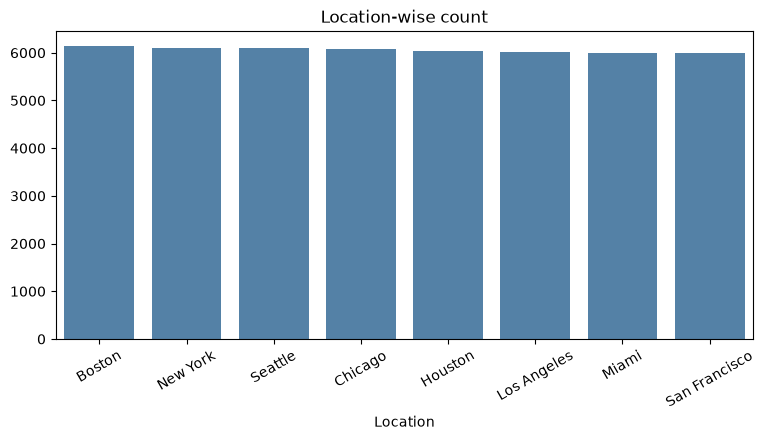


List of locations: ['Boston', 'Chicago', 'Houston', 'Los Angeles', 'Miami', 'New York', 'San Francisco', 'Seattle']


In [11]:
location_counts = df["Location"].value_counts(dropna=False)
print("Location-wise count (NaN = missing location):")
print(location_counts)

plt.figure(figsize=(9, 4))
sns.barplot(x=location_counts.index.astype(str), y=location_counts.values, color="steelblue")
plt.title("Location-wise count")
plt.xticks(rotation=30)
plt.show()

print("\nList of locations:", sorted(df["Location"].dropna().unique()))

500 rows cannot be split evenly across 8 locations (500 / 8 = 62.5), so 4 randomly chosen locations get 63 rows and the other 4 get 62 rows. Total = exactly 500, and every location is represented almost equally.

In [12]:
known = df.dropna(subset=["Location"])
locs = pd.Series(known["Location"].unique()).sample(frac=1, random_state=42).tolist()
n_per_loc = {loc: (63 if i < 4 else 62) for i, loc in enumerate(locs)}

sample_equal = pd.concat(
    [known[known["Location"] == loc].sample(n=n, random_state=42) for loc, n in n_per_loc.items()]
)
print(sample_equal.shape)
print(sample_equal["Location"].value_counts())

(500, 12)
Location
New York         63
Miami            63
San Francisco    63
Seattle          63
Chicago          62
Houston          62
Boston           62
Los Angeles      62
Name: count, dtype: int64


# Cluster 

In [13]:
locations = df["Location"].dropna().unique()
selected_locations = pd.Series(locations).sample(n=2, random_state=42)
print("Selected clusters:", selected_locations.tolist())
sample_cluster = df[df["Location"].isin(selected_locations)]
print(sample_cluster.shape)
sample_cluster.head(36)
#sample_cluster.count()

Selected clusters: ['New York', 'Miami']
(12101, 12)


,Transaction_ID,User_ID,Transaction_Amount,Transaction_Type,Time_of_Transaction,Device_Used,Location,Previous_Fraudulent_Transactions,Account_Age,Number_of_Transactions_Last_24H,Payment_Method,Fraudulent
1,T2,4507,1554.58,ATM Withdrawal,13.0,Mobile,New York,4,79,3,Credit Card,0
16,T17,4171,3960.52,Bank Transfer,13.0,Tablet,Miami,2,68,8,Debit Card,0
17,T18,3919,2327.71,Online Purchase,20.0,NaN,Miami,4,21,1,Debit Card,0
20,T21,2685,973.51,Bill Payment,2.0,Mobile,New York,1,43,12,UPI,0
21,T22,4380,2553.98,ATM Withdrawal,3.0,Mobile,Miami,1,7,9,Net Banking,0
22,T23,1769,2222.86,POS Payment,14.0,Mobile,Miami,1,103,10,UPI,0
25,T26,4485,NaN,Online Purchase,17.0,Mobile,Miami,2,63,8,UPI,0
26,T27,3853,4065.44,Online Purchase,21.0,Tablet,New York,4,99,9,Net Banking,0
30,T31,3324,428.39,POS Payment,20.0,Desktop,New York,0,85,10,Credit Card,0
32,T33,1459,2212.25,Online Purchase,10.0,Desktop,New York,4,14,13,UPI,0


`Location` has only 8 values, so the 5 most-listed and 5 least-listed groups necessarily overlap (they share 2 locations). The overlap is shown below; each group is then sampled (100 rows each).

In [14]:
loc_rank = df["Location"].value_counts()
top5 = loc_rank.head(5).index.tolist()
bottom5 = loc_rank.tail(5).index.tolist()
print("Top 5 most listed :", top5)
print("Top 5 least listed:", bottom5)
print("Overlap           :", sorted(set(top5) & set(bottom5)))

sample_top5 = df[df["Location"].isin(top5)].sample(n=100, random_state=42)
sample_bottom5 = df[df["Location"].isin(bottom5)].sample(n=100, random_state=42)

print("\nSample from top 5:")
print(sample_top5["Location"].value_counts())
print("\nSample from least 5:")
print(sample_bottom5["Location"].value_counts())

Top 5 most listed : ['Boston', 'New York', 'Seattle', 'Chicago', 'Houston']
Top 5 least listed: ['Chicago', 'Houston', 'Los Angeles', 'Miami', 'San Francisco']
Overlap           : ['Chicago', 'Houston']



Sample from top 5:
Location
Seattle     23
Chicago     22
Boston      22
Houston     18
New York    15
Name: count, dtype: int64

Sample from least 5:
Location
San Francisco    25
Chicago          25
Los Angeles      22
Miami            21
Houston           7
Name: count, dtype: int64


# Data Selection

### 1. Missing Value

                     Missing  Missing_%
Transaction_Amount      2520       4.94
Time_of_Transaction     2552       5.00
Device_Used             2473       4.85
Location                2547       4.99
Payment_Method          2469       4.84


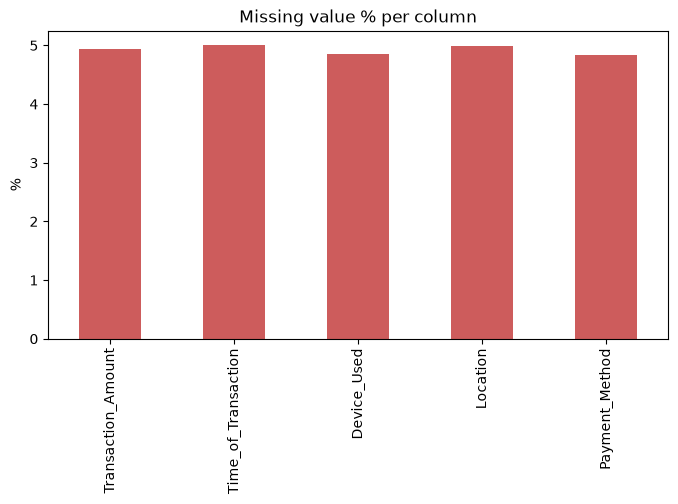

In [15]:
missing = pd.DataFrame({"Missing": df.isnull().sum(), "Missing_%": (df.isnull().mean() * 100).round(2)})
print(missing[missing["Missing"] > 0])

plt.figure(figsize=(8, 4))
missing[missing["Missing"] > 0]["Missing_%"].plot(kind="bar", color="indianred")
plt.title("Missing value % per column")
plt.ylabel("%")
plt.show()

In [16]:
# Impute missing values: median for numeric, mode for categorical
df_clean = df.copy()
for col in df_clean.columns:
    if df_clean[col].isnull().any():
        if df_clean[col].dtype == "object" or str(df_clean[col].dtype) == "str":
            df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])
        else:
            df_clean[col] = df_clean[col].fillna(df_clean[col].median())
print("Remaining missing values:", df_clean.isnull().sum().sum())

Remaining missing values: 0


### 2. Identical Values

In [17]:
print("Fully duplicate rows:", df_clean.duplicated().sum())

ident = pd.DataFrame({
    "Unique_Values": df_clean.nunique(),
    "Most_Common_Value_%": [round(df_clean[c].value_counts(normalize=True).iloc[0] * 100, 2) for c in df_clean.columns],
})
print(ident)
print("\nConstant columns (one identical value):", ident[ident["Unique_Values"] == 1].index.tolist())
print("ID-like columns (all values different):", ident[ident["Unique_Values"] == len(df_clean)].index.tolist())

Fully duplicate rows: 881


                                  Unique_Values  Most_Common_Value_%
Transaction_ID                            50000                 0.00
User_ID                                    4000                 0.05
Transaction_Amount                        44822                 4.94
Transaction_Type                              5                20.27
Time_of_Transaction                          24                 8.89
Device_Used                                   4                35.82
Location                                      8                17.05
Previous_Fraudulent_Transactions              5                20.24
Account_Age                                 119                 0.94
Number_of_Transactions_Last_24H              14                 7.41
Payment_Method                                5                28.15
Fraudulent                                    2                95.08

Constant columns (one identical value): []
ID-like columns (all values different): []


`Transaction_ID` is unique for every row, so it carries no pattern and is dropped. `User_ID` is also an identifier and is excluded from the model. No column is constant, so none is dropped for identical values.

### 3. Correlation Analysis

Number_of_Transactions_Last_24H    -0.003877
Previous_Fraudulent_Transactions    0.001136
Transaction_Amount                  0.005359
Account_Age                         0.006203
Time_of_Transaction                 0.006902
User_ID                             0.008046
Fraudulent                          1.000000
Name: Fraudulent, dtype: float64


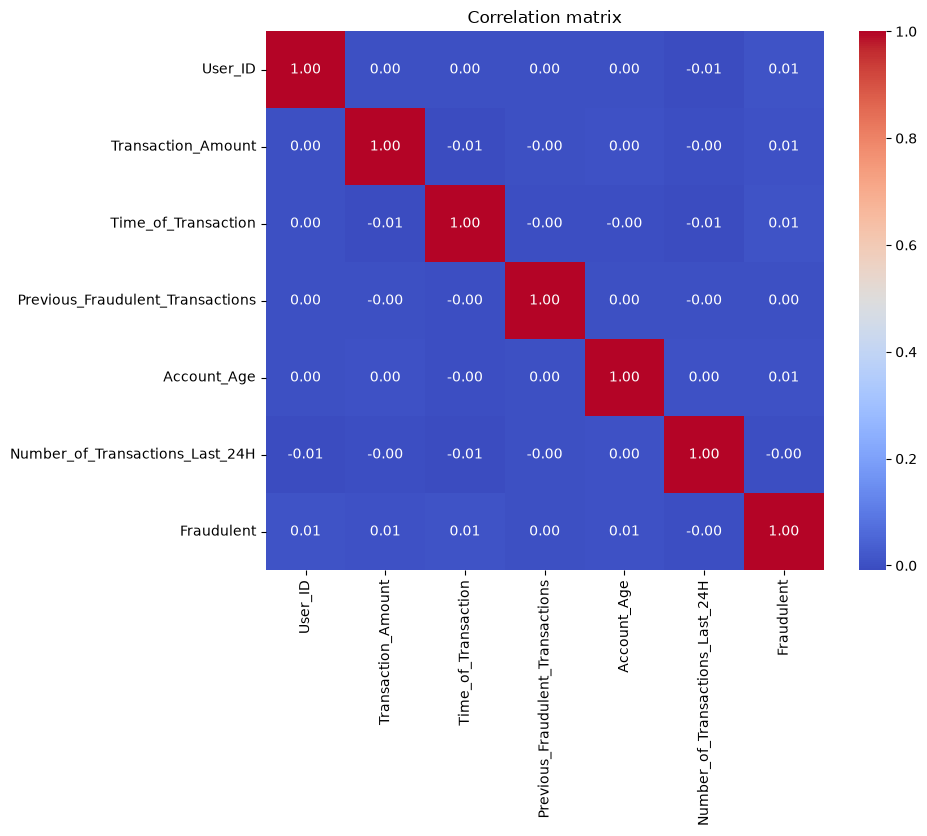

In [18]:
corr = df_clean.corr(numeric_only=True)

print(corr["Fraudulent"].sort_values())

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation matrix")
plt.show()

All correlations with `Fraudulent` are close to 0 (below 0.01), so no single numeric feature is linearly related to fraud.

### 4. Chi-Square Test

Chi-square needs non-negative inputs. Categorical columns are one-hot encoded and numeric columns are min-max scaled to [0, 1].

In [19]:
X = df_clean.drop(["Fraudulent", "Transaction_ID", "User_ID"], axis=1)

Y = df_clean["Fraudulent"]
X.head()

,Transaction_Amount,Transaction_Type,Time_of_Transaction,Device_Used,Location,Previous_Fraudulent_Transactions,Account_Age,Number_of_Transactions_Last_24H,Payment_Method
0,1292.76,ATM Withdrawal,16.0,Tablet,San Francisco,0,119,13,Debit Card
1,1554.58,ATM Withdrawal,13.0,Mobile,New York,4,79,3,Credit Card
2,2395.02,ATM Withdrawal,12.0,Mobile,Boston,3,115,9,UPI
3,100.10,Bill Payment,15.0,Desktop,Chicago,4,3,4,UPI
4,1490.50,POS Payment,19.0,Mobile,San Francisco,2,57,7,Credit Card


In [20]:
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
num_cols = X.select_dtypes(include="number").columns.tolist()

X_enc = pd.get_dummies(X, columns=cat_cols, dtype=int)
X_enc[num_cols] = MinMaxScaler().fit_transform(X_enc[num_cols])
print(X_enc.shape)

(51000, 27)


In [21]:
selector = SelectKBest(score_func=chi2, k="all")

selector.fit(X_enc, Y)

chi_table = pd.DataFrame({"Feature": X_enc.columns, "Chi2_Score": selector.scores_, "p_value": selector.pvalues_})
chi_table = chi_table.sort_values("Chi2_Score", ascending=False).reset_index(drop=True)
print(chi_table)

                             Feature  Chi2_Score   p_value
0                   Location_Chicago    4.364404  0.036697
1                   Location_Seattle    4.146041  0.041732
2                 Device_Used_Tablet    1.997846  0.157523
3                 Device_Used_Mobile    1.929452  0.164818
4   Transaction_Type_Online Purchase    1.568293  0.210455
5    Transaction_Type_ATM Withdrawal    1.558794  0.211842
6                   Location_Houston    0.778234  0.377682
7               Location_Los Angeles    0.708232  0.400031
8                Time_of_Transaction    0.417811  0.518031
9                  Location_New York    0.401030  0.526558
10                       Account_Age    0.333020  0.563886
11    Transaction_Type_Bank Transfer    0.286652  0.592374
12                Transaction_Amount    0.238806  0.625070
13                Payment_Method_UPI    0.162859  0.686538
14      Transaction_Type_POS Payment    0.157616  0.691361
15   Number_of_Transactions_Last_24H    0.146679  0.7017

In [22]:
# Chi-square test of independence for each original categorical column vs Fraudulent
rows = []
for col in cat_cols:
    chi2_stat, p, dof, _ = chi2_contingency(pd.crosstab(X[col], Y))
    rows.append((col, round(chi2_stat, 3), dof, round(p, 4), "Dependent" if p < 0.05 else "Independent"))
pd.DataFrame(rows, columns=["Column", "Chi2", "DoF", "p_value", "Result (alpha=0.05)"])

,Column,Chi2,DoF,p_value,Result (alpha=0.05)
0,Transaction_Type,3.591,4,0.4641,Independent
1,Device_Used,3.930,3,0.2692,Independent
2,Location,10.517,7,0.1611,Independent
3,Payment_Method,0.380,4,0.9841,Independent


A p-value above 0.05 means the feature is statistically independent of `Fraudulent` and adds little predictive signal. This sets the expectation for the ML model in Task 5: fraud in this dataset will be hard to predict.

In [23]:
#Split

In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X_enc, Y, test_size=0.30, random_state=42, stratify=Y
)
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Fraud share  train:", round(y_train.mean() * 100, 2), "%  test:", round(y_test.mean() * 100, 2), "%")

Train: (35700, 27) Test: (15300, 27)
Fraud share  train: 4.92 %  test: 4.92 %


Task 5: 
ML Model

Fraud is only about 5% of the rows, so accuracy alone is misleading. Three models are compared and judged on precision, recall, F1 and ROC-AUC for the fraud class:
1. Logistic Regression (baseline)
2. Random Forest
3. Random Forest trained on SMOTE-balanced training data (SMOTE is applied to the training set only, never to the test set)

In [25]:
def evaluate(name, model, Xtr, ytr, Xte, yte):
    model.fit(Xtr, ytr)
    pred = model.predict(Xte)
    proba = model.predict_proba(Xte)[:, 1]
    res = {
        "Model": name,
        "Accuracy": round((pred == yte).mean(), 4),
        "Precision": round(precision_score(yte, pred, zero_division=0), 4),
        "Recall": round(recall_score(yte, pred), 4),
        "F1": round(f1_score(yte, pred), 4),
        "ROC_AUC": round(roc_auc_score(yte, proba), 4),
    }
    return res, pred

results, preds = [], {}

r, p = evaluate("Logistic Regression", LogisticRegression(max_iter=1000), X_train, y_train, X_test, y_test)
results.append(r); preds[r["Model"]] = p

r, p = evaluate("Random Forest", RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1), X_train, y_train, X_test, y_test)
results.append(r); preds[r["Model"]] = p

X_sm, y_sm = SMOTE(random_state=42).fit_resample(X_train, y_train)
print("After SMOTE:", Counter(y_sm))
r, p = evaluate("Random Forest + SMOTE", RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1), X_sm, y_sm, X_test, y_test)
results.append(r); preds[r["Model"]] = p

results_df = pd.DataFrame(results).set_index("Model")
results_df

After SMOTE: Counter({0: 33943, 1: 33943})


,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Logistic Regression,0.9508,0.0000,0.0000,0.0000,0.4903
Random Forest,0.9522,1.0000,0.0292,0.0568,0.5179
Random Forest + SMOTE,0.9435,0.1744,0.0398,0.0649,0.5206


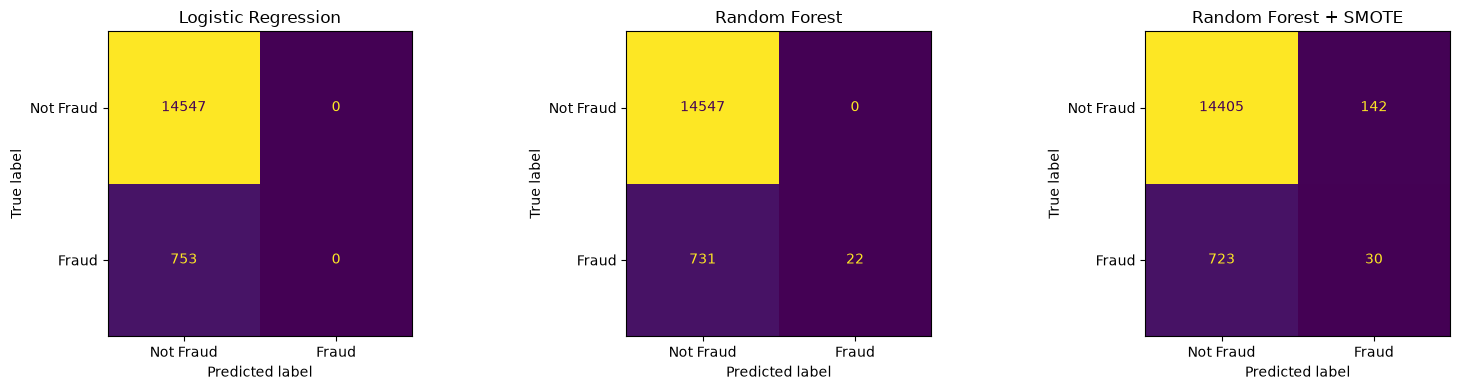

              precision    recall  f1-score   support

   Not Fraud       0.95      0.99      0.97     14547
       Fraud       0.17      0.04      0.06       753

    accuracy                           0.94     15300
   macro avg       0.56      0.52      0.52     15300
weighted avg       0.91      0.94      0.93     15300



In [26]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, p) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, p), display_labels=["Not Fraud", "Fraud"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

print(classification_report(y_test, preds["Random Forest + SMOTE"], target_names=["Not Fraud", "Fraud"]))

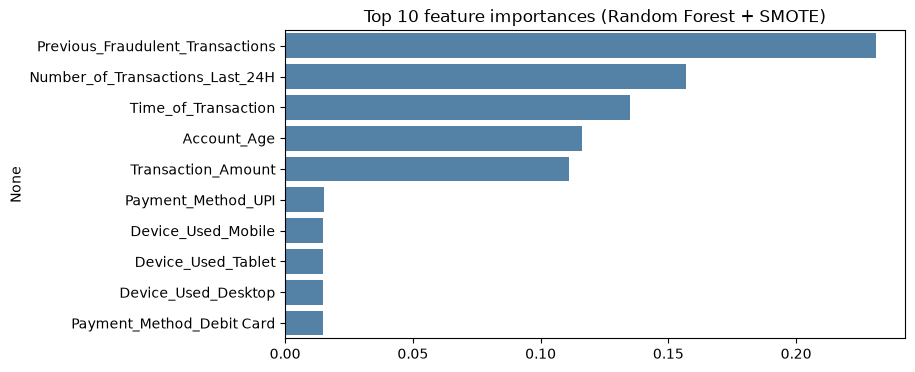

In [27]:
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1).fit(X_sm, y_sm)
imp = pd.Series(rf.feature_importances_, index=X_enc.columns).sort_values(ascending=False).head(10)
plt.figure(figsize=(8, 4))
sns.barplot(x=imp.values, y=imp.index, color="steelblue")
plt.title("Top 10 feature importances (Random Forest + SMOTE)")
plt.show()

# Result Analysis

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Logistic Regression | 0.9508 | 0.0000 | 0.0000 | 0.0000 | 0.4903 |
| Random Forest | 0.9522 | 1.0000 | 0.0292 | 0.0568 | 0.5179 |
| Random Forest + SMOTE | 0.9435 | 0.1744 | 0.0398 | 0.0649 | 0.5206 |

**Key findings**
- **Accuracy is misleading.** About 95% of transactions are not fraud, so a model that predicts "Not Fraud" every time scores about 95%. Logistic Regression does exactly this: 0 frauds caught (recall 0).
- **SMOTE helps slightly, not decisively.** Balancing the training data raised recall from 2.9% to 4.0% and F1 from 0.057 to 0.065, but precision fell from 1.00 (only a handful of predictions) to 0.17, and ROC-AUC stays near 0.5 (random guessing).
- **Why the models fail:** the data-selection steps already predicted this. Every correlation with `Fraudulent` is below 0.01, and the chi-square tests of independence (`Transaction_Type`, `Device_Used`, `Location`, `Payment_Method`) all give p > 0.05, so these features carry almost no information about fraud. (At the one-hot level `Location_Chicago` and `Location_Seattle` reach p < 0.05, but the column as a whole is not significant, and with 25 tests one or two such hits are expected by chance.)
- **Sampling tasks:** the stratified, equalized (63/62 per location = 500) and cluster samples were all drawn successfully. `Location` has only 8 values, so the "5 most / 5 least listed" groups overlap on Chicago and Houston.
- **Data quality:** about 5% missing in each of 5 columns (imputed with median/mode), 881 duplicate rows after imputation, no constant columns, and an "Invalid Method" payment category (3%).

**Conclusion:** with the features available, fraud in this dataset is essentially not predictable (best F1 about 0.06). Of the three, Random Forest + SMOTE is the best compromise, since it is the only one with usable recall and precision together, but it is not reliable enough for deployment. Better results would need richer features, such as per-user transaction history or velocity features, or a different data source.